# Módulo 48: Interactividad — Solución
*Juliho Castillo*

Enunciado para estudiantes: [m48-interactividad-guia.ipynb](m48-interactividad-guia.ipynb) · Lección: [m48-interactividad-leccion.ipynb](m48-interactividad-leccion.ipynb)

## Contexto

Los gerentes quieren hacer sus propias preguntas sobre el informe de ventas: acotar un periodo, ver la evolución de un país al pasar el cursor y abrir el detalle de los productos de un país sin perder los filtros. La solución prepara los datos en este notebook y los presenta en la app [`m48-interactividad-app.py`](m48-interactividad-app.py), que se prueba con `AppTest`. El enunciado original del curso se perdió; las instrucciones de la guía se reconstruyeron a partir de la solución.

Los fragmentos de la app que aparecen en cada tarea se leen directamente del archivo, así que siempre coinciden con el código que se ejecuta.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "png"
pio.defaults.default_width = 900
pio.defaults.default_height = 450

sys.path.insert(0, str(Path("../practica-ventas").resolve()))
import ventas as practica

con = practica.conectar()

import datetime as dt

from IPython.display import Markdown
from streamlit import config
from streamlit.logger import set_log_level
from streamlit.testing.v1 import AppTest

config.get_option("logger.level")  # lee la configuración antes de silenciar los avisos
set_log_level("critical")          # sin avisos de Streamlit fuera de "streamlit run"
pio.templates.default = "plotly"   # import streamlit la cambia a "streamlit", pensada para la app
APP = Path("m48-interactividad-app.py").resolve()
FUENTE = APP.read_text(encoding="utf-8")


def seccion(numero):
    # Muestra el bloque de la app que empieza con "# --- <numero>."
    inicio = FUENTE.index(f"# --- {numero}.")
    fin = FUENTE.find("\n# --- ", inicio + 1)
    return Markdown(f"```python\n{FUENTE[inicio:fin if fin != -1 else None].strip()}\n```")

### Tarea 1. Datos de la página de análisis

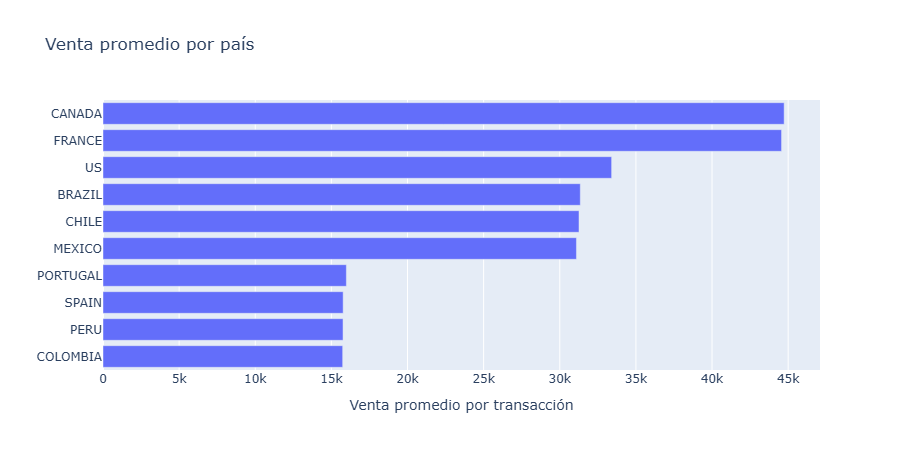

,pais,ventas_promedio,ventas_total
1,CANADA,44736.0,6683524091
0,FRANCE,44566.0,6709452115
2,US,33406.0,5025305951


In [2]:
por_pais = practica.ventas_por(con, "pais").sort_values("ventas_promedio")
figura = px.bar(por_pais, x="ventas_promedio", y="pais", orientation="h",
                labels={"ventas_promedio": "Venta promedio por transacción", "pais": ""},
                title="Venta promedio por país")
figura.update_layout(separators=", ")
figura.show()
por_pais.sort_values("ventas_promedio", ascending=False)[["pais", "ventas_promedio", "ventas_total"]].head(3).round(0)

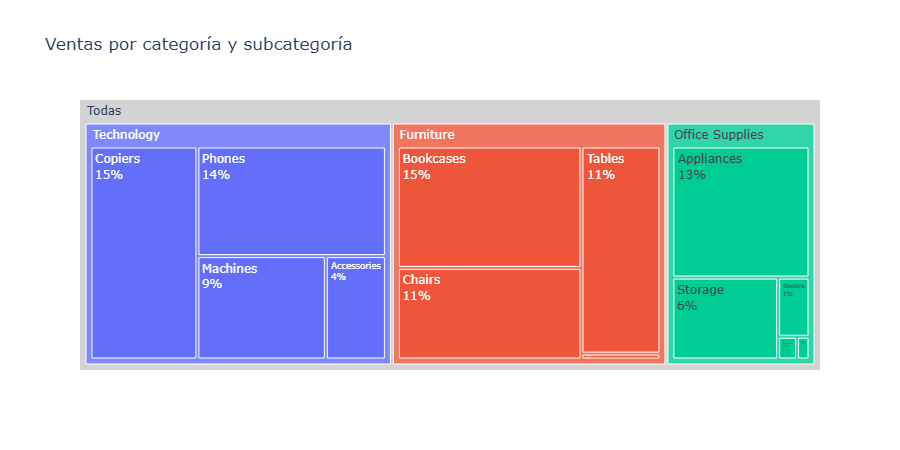

,categoria,subcategoria,ventas_total
0,Technology,Copiers,6383204325
1,Furniture,Bookcases,6278627615
2,Technology,Phones,5792285031


In [3]:
por_subcategoria = practica.ventas_por(con, ["categoria", "subcategoria"])
treemap = px.treemap(por_subcategoria, path=[px.Constant("Todas"), "categoria", "subcategoria"],
                     values="ventas_total", title="Ventas por categoría y subcategoría")
treemap.update_traces(textinfo="label+percent root", root_color="lightgrey")
treemap.show()
por_subcategoria.head(3)[["categoria", "subcategoria", "ventas_total"]]

CANADA tiene la venta promedio por transacción más alta (44 736), casi empatada con FRANCE (44 566), que es el país con más ventas totales; US, tercero en ventas totales, vende bastante menos por transacción (33 406). La venta promedio y el total responden preguntas distintas, y por eso en la app el total va en el eje y la venta promedio en la información sobre herramientas. Copiers es la subcategoría con más ventas, por delante de Bookcases y Phones.

### Tarea 2. Esqueleto de la app y filtros

In [4]:
seccion(1)

```python
# --- 1. Conexión y consultas en caché ---------------------------------------
@st.cache_resource
def conexion():
    # Una sola conexión DuckDB para todas las sesiones y todas las ejecuciones
    return practica.conectar()


@st.cache_data(show_spinner=False)
def opciones():
    con = conexion()
    paises = practica.ventas_por(con, "pais")["pais"].tolist()  # de mayor a menor venta
    categorias = sorted(practica.ventas_por(con, "categoria")["categoria"])
    inicio, fin = con.execute("SELECT min(fecha), max(fecha) FROM ventas").fetchone()
    return paises, categorias, inicio, fin


# Los filtros llegan como un diccionario de tuplas y fechas: es hashable para la caché
@st.cache_data(max_entries=200, show_spinner=False)
def kpis(filtros: dict) -> dict:
    return practica.kpis(conexion(), **filtros)


@st.cache_data(max_entries=200, show_spinner=False)
def ventas_por(columnas: tuple, filtros: dict) -> pd.DataFrame:
    return practica.ventas_por(conexion(), list(columnas), **filtros)


@st.cache_data(max_entries=200, show_spinner=False)
def serie(nivel: str, filtros: dict) -> pd.DataFrame:
    return practica.serie_temporal(conexion(), nivel, **filtros)


@st.cache_data(max_entries=200, show_spinner=False)
def tabla_con_minigrafico(filtros: dict) -> pd.DataFrame:
    tabla = practica.tabla_por_pais(conexion(), **filtros)
    mensual = practica.ventas_por(conexion(), ["pais", "anio_mes"], **filtros).sort_values("anio_mes")
    # Una lista de cantidades mensuales por país: la celda que dibuja LineChartColumn
    tendencia = mensual.groupby("pais")["cantidad_total"].agg(list).rename("cantidad_mensual")
    return tabla.merge(tendencia, on="pais")
```

In [5]:
seccion(3)

```python
# --- 3. Barra lateral: filtros -----------------------------------------------
PAISES, CATEGORIAS, INICIO, FIN = opciones()


def restablecer():
    # Un callback se ejecuta antes que el script: aquí sí se puede cambiar el estado de los widgets
    st.session_state["paises"] = PAISES
    st.session_state["categorias"] = CATEGORIAS
    st.session_state["fechas"] = (INICIO, FIN)
    st.query_params.pop("detalle", None)


# Estado inicial de los filtros, en un solo lugar y antes de crear los widgets
st.session_state.setdefault("paises", PAISES)
st.session_state.setdefault("categorias", CATEGORIAS)
st.session_state.setdefault("fechas", (INICIO, FIN))

with st.sidebar:
    st.header("Filtros")
    # Con el valor en session_state no hace falta default=: el widget lo toma de su key
    paises = st.multiselect("Países", PAISES, key="paises")
    categorias = st.pills("Categorías", CATEGORIAS, selection_mode="multi", key="categorias")
    desde, hasta = st.slider("Rango de fechas", min_value=INICIO, max_value=FIN, format="DD/MM/YYYY", key="fechas")
    st.button("Restablecer filtros", icon=":material/restart_alt:", on_click=restablecer, width="stretch")

if not paises or not categorias:
    st.warning("Elige al menos un país y una categoría en la barra lateral.", icon=":material/filter_alt_off:")
    st.stop()

# Filtros de la barra lateral: llegan a todos los elementos de la página
filtros = {"paises": tuple(paises), "categorias": tuple(categorias), "desde": desde, "hasta": hasta}

# Reservamos el sitio del título y los KPIs: se rellenan cuando se conoce la selección del gráfico
cabecera = st.container()
```

La conexión es un recurso compartido (`cache_resource`) y cada consulta se guarda por sus argumentos (`cache_data`); los filtros son un diccionario de tuplas y fechas, hashable. El estado inicial de los widgets se fija con `setdefault` antes de crearlos, lo que permite que el botón "Restablecer filtros" los cambie desde un callback. Comprobación con `AppTest`: al acotar el rango de fechas a 2020 cambian las métricas.

In [6]:
def metricas(at):
    return {m.label: m.value for m in at.metric}


at = AppTest.from_file(str(APP), default_timeout=60).run()
print("Sin filtros:", metricas(at))
at.slider[0].set_range(dt.date(2020, 1, 1), dt.date(2020, 12, 31)).run()
print("Año 2020:   ", metricas(at))
assert not at.exception

Sin filtros: {'Ventas': '41 941,0 M', 'Unidades': '148 055 781', 'Transacciones': '1 499 000', 'Venta promedio': '27 979'}


Año 2020:    {'Ventas': '4 574,0 M', 'Unidades': '24 546 531', 'Transacciones': '499 000', 'Venta promedio': '9 166'}


### Tarea 3. Título dinámico

In [7]:
seccion(2)

```python
# --- 2. Funciones puras: selección y título ----------------------------------
def pais_del_punto(punto: dict) -> str:
    # custom_data[0] es el país; en barras horizontales también está en "y"
    datos = punto.get("customdata")
    return datos[0] if datos else punto.get("y")


def paises_de_seleccion(seleccion, disponibles: list[str]) -> list[str] | None:
    """Países seleccionados en el gráfico, en el orden de `disponibles`.

    Devuelve None si no hay selección (sin filtro cruzado). Los países que ya no
    están entre los disponibles (porque cambió la barra lateral) se descartan.
    """
    puntos = (seleccion or {}).get("points", [])
    elegidos = {pais_del_punto(punto) for punto in puntos}
    paises = [pais for pais in disponibles if pais in elegidos]
    return paises or None


def lista_legible(elegidos, todos, todos_texto: str, unidad: str, maximo: int = 3) -> str:
    """"todos los países", "US y CANADA" o "5 países", según cuántos haya."""
    elegidos = list(elegidos)
    if set(elegidos) == set(todos):
        return todos_texto
    if len(elegidos) > maximo:
        return f"{len(elegidos)} {unidad}"
    if len(elegidos) == 1:
        return elegidos[0]
    return ", ".join(elegidos[:-1]) + " y " + elegidos[-1]


def titulo_dinamico(paises, todos_paises, categorias, todas_categorias, desde, hasta) -> str:
    return (
        f"Ventas de {lista_legible(paises, todos_paises, 'todos los países', 'países')}"
        f" · {lista_legible(categorias, todas_categorias, 'todas las categorías', 'categorías')}"
        f" · del {desde:%d/%m/%Y} al {hasta:%d/%m/%Y}"
    )


def millones(valor) -> str:
    return f"{valor / 1e6:,.1f} M".replace(",", " ").replace(".", ",")


def entero(valor) -> str:
    return f"{valor:,.0f}".replace(",", " ")
```

In [8]:
exec(FUENTE[FUENTE.index("def pais_del_punto"):FUENTE.index("def millones")])  # las funciones puras de la app

PAISES = practica.ventas_por(con, "pais")["pais"].tolist()
CATEGORIAS = sorted(practica.ventas_por(con, "categoria")["categoria"])
casos = [
    (PAISES, CATEGORIAS, dt.date(2019, 1, 1), dt.date(2021, 12, 31)),
    (["US", "CANADA"], ["Technology"], dt.date(2020, 1, 1), dt.date(2020, 12, 31)),
    (PAISES[:5], CATEGORIAS[:2], dt.date(2021, 1, 1), dt.date(2021, 6, 30)),
]
for paises, categorias, desde, hasta in casos:
    print(titulo_dinamico(paises, PAISES, categorias, CATEGORIAS, desde, hasta))

Ventas de todos los países · todas las categorías · del 01/01/2019 al 31/12/2021
Ventas de US y CANADA · Technology · del 01/01/2020 al 31/12/2020
Ventas de 5 países · Furniture y Office Supplies · del 01/01/2021 al 30/06/2021


Las funciones se ejecutan aquí tal como están en la app (se toman del archivo), así que la prueba cubre el código real. En la app, el título se escribe al final, en un contenedor reservado arriba, porque depende también de la selección del gráfico:

In [9]:
seccion(9)

```python
# --- 9. Título dinámico y KPIs (en el contenedor reservado arriba) -----------
with cabecera:
    st.title(titulo_dinamico(seleccion or paises, PAISES, categorias, CATEGORIAS, desde, hasta))
    if seleccion:
        st.caption(f"Filtro cruzado activo desde el gráfico de países: {', '.join(seleccion)}.")
    resumen = kpis(filtros_cruzados)
    with st.container(horizontal=True):
        st.metric("Ventas", millones(resumen["ventas_total"]), border=True)
        st.metric("Unidades", entero(resumen["cantidad_total"]), border=True)
        st.metric("Transacciones", entero(resumen["transacciones"]), border=True)
        st.metric("Venta promedio", entero(resumen["ventas_promedio"]), border=True)
```

### Tarea 4. Filtro cruzado y jerarquía

In [10]:
seccion(4)

```python
# --- 4. Filtro cruzado: gráfico de países seleccionable ----------------------
def al_seleccionar():
    # Si se selecciona un solo país, se abre su detalle (y queda en la URL)
    seleccion = st.session_state["grafico_paises"]["selection"]
    elegidos = paises_de_seleccion(seleccion, PAISES)
    if elegidos and len(elegidos) == 1:
        st.query_params["detalle"] = elegidos[0]


columna_paises, columna_productos = st.columns([2, 3])

with columna_paises.container(border=True):
    st.subheader("Ventas por país")
    por_pais = ventas_por(("pais",), filtros).sort_values("ventas_total")
    figura = px.bar(
        por_pais,
        x="ventas_total",
        y="pais",
        orientation="h",
        custom_data=["pais", "ventas_promedio", "transacciones", "cantidad_total"],
        labels={"ventas_total": "Ventas", "pais": ""},
    )
    figura.update_traces(
        hovertemplate=(
            "<b>%{customdata[0]}</b><br>"
            "Ventas: %{x:,.0f}<br>"
            "Venta promedio: %{customdata[1]:,.0f}<br>"
            "Transacciones: %{customdata[2]:,}<br>"
            "Unidades: %{customdata[3]:,}<extra></extra>"
        )
    )
    figura.update_layout(height=380, margin=dict(l=0, r=10, t=10, b=0), separators=", ")
    evento = st.plotly_chart(
        figura,
        key="grafico_paises",
        on_select=al_seleccionar,
        selection_mode=("points", "box"),
        alt="Ventas totales por país; seleccionar barras filtra el resto del tablero",
    )
    st.caption("Haz clic en una barra (Mayús + clic para varias) para filtrar el tablero; doble clic para quitar la selección.")

seleccion = paises_de_seleccion(evento.selection, paises)
# Filtro cruzado: la selección del gráfico se suma a los filtros de la barra lateral
filtros_cruzados = {**filtros, "paises": tuple(seleccion)} if seleccion else filtros
```

In [11]:
def punto(pais):
    # Selección simulada: AppTest no puede hacer clic en un gráfico
    return {"curve_number": 0, "y": pais, "customdata": [pais]}


assert paises_de_seleccion({"points": []}, PAISES) is None
assert paises_de_seleccion({"points": [punto("US")]}, PAISES) == ["US"]
assert paises_de_seleccion({"points": [punto("PERU"), punto("US")]}, PAISES) == ["US", "PERU"]
assert paises_de_seleccion({"points": [punto("US")]}, ["CANADA"]) is None
print("La función de selección pasa las cuatro pruebas.")

La función de selección pasa las cuatro pruebas.


In [12]:
seccion(5)

```python
# --- 5. Jerarquía: treemap categoría → subcategoría → producto ---------------
with columna_productos.container(border=True):
    st.subheader("Ventas por categoría, subcategoría y producto")
    jerarquia = ventas_por(("categoria", "subcategoria", "producto"), filtros_cruzados)
    treemap = px.treemap(
        jerarquia,
        path=[px.Constant("Todas"), "categoria", "subcategoria", "producto"],
        values="ventas_total",
        maxdepth=3,  # se ven dos niveles; un clic en una subcategoría baja a sus productos
    )
    treemap.update_traces(
        hovertemplate="<b>%{label}</b><br>Ventas: %{value:,.0f}<br>%{percentRoot:.1%} del total<extra></extra>",
        root_color="lightgrey",
    )
    treemap.update_layout(height=380, margin=dict(l=0, r=0, t=10, b=0), separators=", ")
    st.plotly_chart(treemap, alt="Treemap de ventas por categoría y subcategoría; clic para bajar a productos")
    st.caption("Clic en un rectángulo para bajar un nivel; clic en la barra superior para subir.")
```

El gráfico de países recibe solo los filtros de la barra lateral; el resto recibe `filtros_cruzados`, que añade la selección. Un clic en una barra deja un solo país (y abre su detalle); con Mayús + clic o con la selección de caja se eligen varios. El treemap muestra categorías y subcategorías y, con `maxdepth=3`, un clic en una subcategoría baja a sus productos.

### Tarea 5. Información sobre herramientas

In [13]:
mensual = practica.ventas_por(con, ["pais", "anio_mes"]).sort_values("anio_mes")
tendencia = mensual.groupby("pais")["cantidad_total"].agg(list).rename("cantidad_mensual")
print("Meses por país:", tendencia.map(len).to_dict())
tendencia.head(3)

Meses por país:

 {'BRAZIL': 36, 'CANADA': 36, 'CHILE': 36, 'COLOMBIA': 36, 'FRANCE': 36, 'MEXICO': 36, 'PERU': 36, 'PORTUGAL': 36, 'SPAIN': 36, 'US': 36}


pais
BRAZIL    [355655, 331617, 639101, 165461, 162192, 63050...
CANADA    [356735, 327533, 655588, 159270, 168468, 62822...
CHILE     [370046, 313162, 628963, 161272, 167349, 64910...
Name: cantidad_mensual, dtype: object

In [14]:
seccion(7)

```python
# --- 7. Tabla por país con minigráfico ---------------------------------------
with st.container(border=True):
    st.subheader("Resumen por país")
    tabla = tabla_con_minigrafico(filtros_cruzados)
    st.dataframe(
        tabla,
        hide_index=True,
        column_order=["pais", "ventas_total", "ventas_promedio", "pct_cantidad", "cantidad_mensual"],
        column_config={
            "pais": st.column_config.TextColumn("País", pinned=True),
            "ventas_total": st.column_config.NumberColumn("Ventas", format="localized"),
            "ventas_promedio": st.column_config.NumberColumn("Venta promedio", format="%.0f"),
            "pct_cantidad": st.column_config.NumberColumn("% de unidades", format="percent"),
            "cantidad_mensual": st.column_config.LineChartColumn(
                "Unidades por mes", width="medium", help="Suma de unidades vendidas en cada mes del rango"
            ),
        },
        alt="Ventas, venta promedio, porcentaje de unidades y tendencia mensual por país",
    )
```

Cada país tiene 36 meses de unidades vendidas, la lista que `LineChartColumn` dibuja como minigráfico. El `hovertemplate` del gráfico de países (Tarea 4) muestra la venta promedio, las transacciones y las unidades a partir de `custom_data`.

### Tarea 6. Obtención de detalles

In [15]:
filtros_detalle = {"paises": ["CANADA"], "categorias": ["Technology"], "desde": "2020-01-01", "hasta": "2020-12-31"}
top = practica.ventas_por(con, ["categoria", "subcategoria", "producto"], **filtros_detalle).head(10)
top[["producto", "subcategoria", "ventas_total", "ventas_promedio"]].round(0)

,producto,subcategoria,ventas_total,ventas_promedio
0,"Motorola Smart Phone, Full Size",Phones,7876887,16208.0
1,"Nokia Smart Phone, Full Size",Phones,7113990,17436.0
2,"Apple Smart Phone, Full Size",Phones,6530551,16617.0
3,"Cisco Smart Phone, Full Size",Phones,5495297,16909.0
4,"Cisco Smart Phone, with Caller ID",Phones,4351459,16866.0
5,"Samsung Smart Phone, Cordless",Phones,4315830,16663.0
6,"Sharp Wireless Fax, Color",Copiers,3890966,18098.0
7,"Canon Wireless Fax, Color",Copiers,3723524,18901.0
8,"Hewlett Wireless Fax, High-Speed",Copiers,3682679,16893.0
9,"Hewlett Copy Machine, Color",Copiers,3474602,16949.0


In [16]:
seccion(8)

```python
# --- 8. Diálogo de detalle por país (obtener detalles) -----------------------
def cerrar_detalle():
    st.query_params.pop("detalle", None)


@st.dialog("Detalle del país", width="large", on_dismiss=cerrar_detalle)
def detalle_pais(pais: str, filtros: dict):
    # Mantiene categorías y fechas de la barra lateral; solo cambia el país
    filtros_pais = {**filtros, "paises": (pais,)}
    st.subheader(f"{pais}: productos más vendidos")
    st.caption(
        f"{lista_legible(filtros['categorias'], CATEGORIAS, 'Todas las categorías', 'categorías')}"
        f" · del {filtros['desde']:%d/%m/%Y} al {filtros['hasta']:%d/%m/%Y}"
    )
    resumen = kpis(filtros_pais)
    with st.container(horizontal=True):
        st.metric("Ventas", millones(resumen["ventas_total"]), border=True)
        st.metric("Unidades", entero(resumen["cantidad_total"]), border=True)
        st.metric("Venta promedio", entero(resumen["ventas_promedio"]), border=True)
    top = ventas_por(("categoria", "subcategoria", "producto"), filtros_pais).head(10)
    st.dataframe(
        top,
        hide_index=True,
        column_order=["producto", "categoria", "subcategoria", "ventas_total", "ventas_promedio"],
        column_config={
            "producto": "Producto",
            "categoria": "Categoría",
            "subcategoria": "Subcategoría",
            "ventas_total": st.column_config.NumberColumn("Ventas", format="localized"),
            "ventas_promedio": st.column_config.NumberColumn("Venta promedio", format="%.0f"),
        },
        alt=f"Los diez productos con más ventas en {pais}",
    )
    if st.button("Volver al tablero", icon=":material/arrow_back:"):
        cerrar_detalle()
        st.rerun()


# El país del detalle viene de la URL: se valida antes de usarlo
pais_detalle = st.query_params.get("detalle")
if pais_detalle in PAISES:
    detalle_pais(pais_detalle, filtros)
```

El diálogo recibe `filtros` (categorías y fechas de la barra lateral) y solo sustituye el país, que es el "mantener todos los filtros" de una página de detalle. El país viaja en `st.query_params`: lo escribe el callback de selección, lo borra el cierre del diálogo, y una URL con `?detalle=CANADA` abre el detalle directamente.

### Tarea 7. Prueba la app

In [17]:
at = AppTest.from_file(str(APP), default_timeout=60).run()
inicial = metricas(at)
at.multiselect[0].set_value(["US", "CANADA"]).run()
at.pills[0].set_value(["Technology"]).run()
at.slider[0].set_range(dt.date(2020, 1, 1), dt.date(2020, 12, 31)).run()
print(at.title[0].value)
print(metricas(at))
assert metricas(at) != inicial and not at.exception

esperado = practica.kpis(con, paises=["US", "CANADA"], categorias=["Technology"], desde="2020-01-01", hasta="2020-12-31")
assert at.metric[2].value == f"{esperado['transacciones']:,}".replace(",", " ")

at.query_params["detalle"] = "CANADA"
at.run()
print(at.subheader[-1].value)
pd.testing.assert_frame_equal(at.dataframe[-1].value.reset_index(drop=True), top.reset_index(drop=True))
print("El diálogo muestra los mismos diez productos que la Tarea 6.")

Ventas de US y CANADA · Technology · del 01/01/2020 al 31/12/2020
{'Ventas': '721,4 M', 'Unidades': '2 059 129', 'Transacciones': '41 880', 'Venta promedio': '17 226'}


CANADA: productos más vendidos
El diálogo muestra los mismos diez productos que la Tarea 6.


La app responde a los tres filtros, sus transacciones coinciden con `practica.kpis` y el diálogo abierto con `?detalle=CANADA` muestra exactamente la tabla calculada en la Tarea 6, con los filtros de categoría y fechas de la barra lateral. La selección en el gráfico, que `AppTest` no puede simular, se probó con las funciones puras (Tarea 4) y en el navegador, lanzando la app con `uv run streamlit run s08-dashboards/m48-interactividad/m48-interactividad-app.py`: un clic en la barra de US abre su detalle y añade `?detalle=US` a la URL, y al cerrar el diálogo el tablero queda filtrado por US.

**Revisión posterior (2026-10):** El ejercicio se resolvió originalmente en Power BI (segmentador de fechas, página de información sobre herramientas y página de obtención de detalles), con capturas de pantalla como evidencia. Se rehízo en Python con DuckDB, Plotly y Streamlit para que la sección no dependa de software de pago ni de Windows; la versión original sigue en el historial de git.